<a href="https://colab.research.google.com/github/eliezermiranda/03/blob/main/03_Redes_Rasas_Atividade_03_Solu%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eliezermiranda/03/blob/main/03_Redes_Rasas_Atividade_03_Solu%C3%A7%C3%A3o.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 03 — SUA PRIMEIRA REDE NEURAL
---

Na aula 2 treinamos uma **reta** com PyTorch. Hoje vamos trocar a reta por uma **rede neural** e ver que ela consegue aprender relações que uma reta não consegue.

**O que você vai aprender**

- montar uma rede neural com `nn.Sequential`;
- o que são **neurônios**, **camadas** e a **função de ativação** ReLU;
- escrever o laço de treinamento dentro de uma **função**, para reutilizá-lo;
- usar o modelo treinado para fazer previsões.

## 0. Importando as bibliotecas

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. Dados
---

Vamos criar dados artificiais em que $y$ **sobe, desce e sobe de novo** conforme $x$ cresce. Pense, por exemplo, na demanda de um produto ao longo de um período, com altos e baixos.

A função `train_test_split` do scikit-learn separa os dados em **treino** (para o modelo aprender) e **teste** (para conferirmos se ele aprendeu de verdade).

In [ ]:
from sklearn.model_selection import train_test_split

x = np.linspace(-3, 3, 120)                                  # 120 valores de x entre -3 e 3
y = np.sin(1.5 * x) + 0.3 * x + np.random.default_rng(42).normal(0, 0.15, 120)

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, random_state=42)

print("exemplos de treino:", len(x_treino))
print("exemplos de teste :", len(x_teste))

exemplos de treino: 84
exemplos de teste : 36


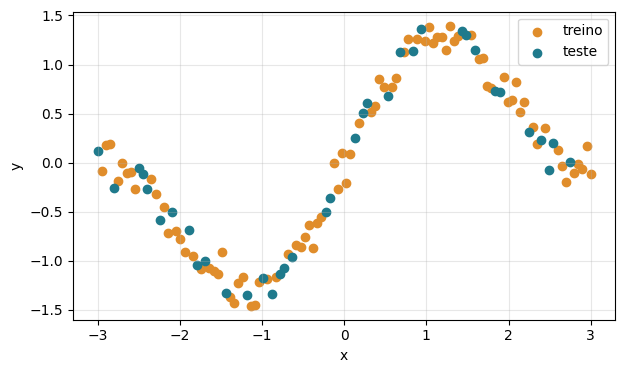

In [ ]:
plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.scatter(x_teste, y_teste, color=AZUL, label="teste")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

---
## 2. Tensores
---

Como na aula passada: convertemos para tensores `float32` e usamos `.reshape(-1, 1)` para que cada **linha** seja um exemplo.

In [ ]:
X_treino = torch.tensor(x_treino, dtype=torch.float32).reshape(-1, 1)
Y_treino = torch.tensor(y_treino, dtype=torch.float32).reshape(-1, 1)
X_teste  = torch.tensor(x_teste,  dtype=torch.float32).reshape(-1, 1)
Y_teste  = torch.tensor(y_teste,  dtype=torch.float32).reshape(-1, 1)

print("X_treino:", X_treino.shape)

X_treino: torch.Size([84, 1])


---
## 3. Primeira tentativa: uma reta
---

Começamos com o modelo da aula passada, `nn.Linear(1, 1)`, para ter uma referência.

Uma novidade: usaremos o otimizador **Adam** em vez do SGD. Ele ajusta o tamanho do passo automaticamente e costuma funcionar bem sem muitos ajustes. Vamos usá-lo como padrão daqui em diante.

In [ ]:
reta = nn.Linear(1, 1)

perda_fn = nn.MSELoss() # erro quadrático médio
otimizador = torch.optim.Adam(reta.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = reta(X_treino)               # 1. prever
    perda = perda_fn(previsao, Y_treino)    # 2. medir o erro
    otimizador.zero_grad()                  # 3. zerar os gradientes antigos
    perda.backward()                        # 4. calcular os gradientes
    otimizador.step()                       # 5. corrigir os parâmetros

print("perda final no treino:", perda.item())

perda final no treino: 0.47738465666770935


Para desenhar o modelo, pedimos previsões para muitos valores de $x$. O bloco `with torch.no_grad():` avisa ao PyTorch que **não** vamos treinar ali, apenas prever.

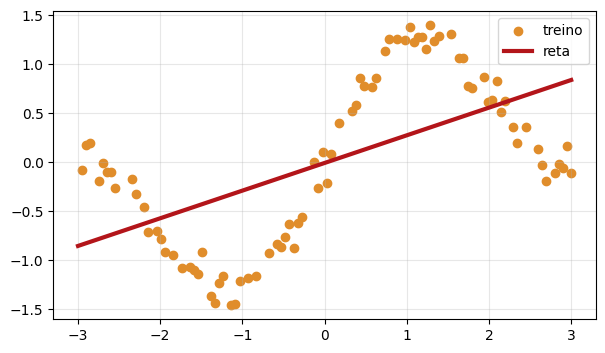

In [ ]:
x_grade = torch.linspace(-3, 3, 200).reshape(-1, 1)     # 200 pontos para desenhar a curva (neste caso, uma reta)

with torch.no_grad():
    y_reta = reta(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=3, label="reta")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

A reta faz o melhor que pode, mas uma reta **nunca** vai subir, descer e subir de novo. Precisamos de um modelo mais flexível.

---
## 4. Uma rede neural
---

Criaremos uma rede neural rasa com os elementos a seguir?

```
entrada x  →  [ nn.Linear(1, 10) ]  →  [ nn.ReLU() ]  →  [ nn.Linear(10, 1) ]  →  saída y
               10 "neurônios"          ativação          junta os 10 em 1
```

- **`nn.Linear(1, 10)`**: transforma o $x$ em 10 números diferentes (cada um é uma reta com seus próprios parâmetros). Esses 10 números são as pré-ativações nos **neurônios** da **camada oculta**.
- **`nn.ReLU()`**: a **função de ativação**. Ela troca os números negativos por zero.
- **`nn.Linear(10, 1)`**: combina os 10 neurônios em uma única saída.

O `nn.Sequential` encaixa as peças na ordem em que aparecem.

### A função ReLU

A ReLU é muito simples: se o número é negativo, vira zero; se é positivo, fica como está.

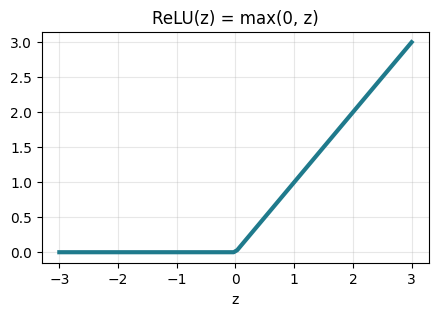

tensor([0., 0., 0., 1., 3.])


In [ ]:
z = torch.linspace(-3, 3, 100)
relu = nn.ReLU()

plt.figure(figsize=(5, 3))
plt.plot(z, relu(z), color=AZUL, linewidth=3)
plt.title("ReLU(z) = max(0, z)"); plt.xlabel("z"); plt.grid(alpha=0.3)
plt.show()

print(relu(torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])))

É justamente esse "dobrar" em zero que dá flexibilidade à rede: combinando várias retas dobradas, ela consegue formar curvas.

> **Por que não tirar a ReLU?** Sem ela, as duas camadas `nn.Linear` em sequência continuariam sendo, no fim das contas, uma reta. A ativação é o que torna a rede **não linear**.

### Montando a rede

In [ ]:
rede = nn.Sequential(
    nn.Linear(1, 10),    # camada oculta: 10 neurônios
    nn.ReLU(),           # ativação
    nn.Linear(10, 1),    # camada de saída
)

print(rede)

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=1, bias=True)
)


Quantos parâmetros essa rede tem? O método `.parameters()` devolve todos eles, e `.numel()` conta quantos números há em cada um.

In [ ]:
total = 0
for p in rede.parameters():
    print(p.shape)
    total = total + p.numel()

print("total de parâmetros:", total)

torch.Size([10, 1])
torch.Size([10])
torch.Size([1, 10])
torch.Size([1])
total de parâmetros: 31


A reta tinha 2 parâmetros. A rede tem 31. Mais parâmetros = mais flexibilidade.

---
## 5. Treinando a rede
---

Repare: o laço de treinamento é **exatamente o mesmo** da reta. Só trocamos `reta` por `rede`.

In [ ]:
perda_fn = nn.MSELoss()
otimizador = torch.optim.Adam(rede.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = rede(X_treino)
    perda = perda_fn(previsao, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 500 == 0:                     # mostra o progresso a cada 500 épocas
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

print("perda final no treino:", perda.item())

época    0 | perda = 0.4980
época  500 | perda = 0.0146
época 1000 | perda = 0.0141
época 1500 | perda = 0.0140
perda final no treino: 0.014045573770999908


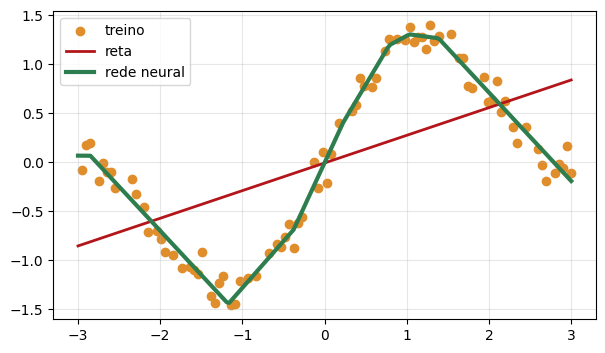

In [ ]:
with torch.no_grad():
    y_rede = rede(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=2, label="reta")
plt.plot(x_grade, y_rede, color=VERDE, linewidth=3, label="rede neural")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Avaliando no teste

Para analisar se o modelo é capaz de generalizar para dados desconhecidos, utilizamos o conjunto de teste.

In [ ]:
with torch.no_grad():
    erro_reta = perda_fn(reta(X_teste), Y_teste).item()
    erro_rede = perda_fn(rede(X_teste), Y_teste).item()

print(f"erro no teste (MSE) - reta: {erro_reta:.4f}")
print(f"erro no teste (MSE) - rede: {erro_rede:.4f}")

erro no teste (MSE) - reta: 0.4664
erro no teste (MSE) - rede: 0.0165


---
## 6. Guardando o treinamento em uma função
---

Vamos treinar várias redes daqui para frente. Para não copiar o laço toda vez, podemos colocar ele dentro de uma **função** no python. A função recebe o modelo, os dados e o número de épocas, treina, e devolve a lista com a perda de cada época.

In [ ]:
def treinar(modelo, X, Y, epocas=2000, lr=0.01):
    perda_fn = nn.MSELoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historico = []

    for epoca in range(epocas):
        previsao = modelo(X)
        perda = perda_fn(previsao, Y)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        historico.append(perda.item())     # guarda a perda desta época

    return historico

Com a função, treinar uma rede nova fica em duas linhas:

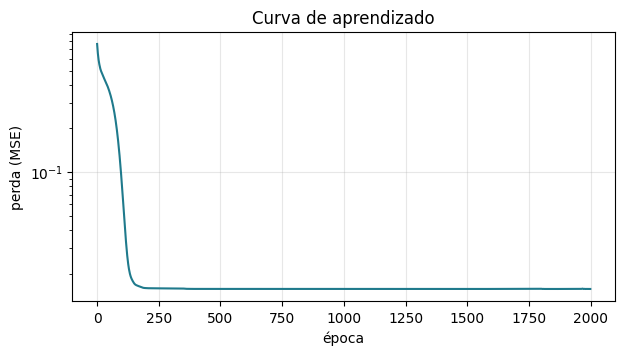

In [ ]:
rede2 = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
historico = treinar(rede2, X_treino, Y_treino)

plt.figure(figsize=(7, 3.5))
plt.plot(historico, color=AZUL)
plt.xlabel("época"); plt.ylabel("perda (MSE)"); plt.title("Curva de aprendizado")
plt.yscale("log"); plt.grid(alpha=0.3)
plt.show()

A **curva de aprendizado** mostra a perda caindo ao longo das épocas. É a primeira coisa a olhar quando treinamos um modelo: se ela não cai, algo está errado.

---
## 7. Quantos neurônios usar?
---

O número de neurônios da camada oculta é uma escolha nossa. Vamos comparar 1, 3, 10 e 100 neurônios.

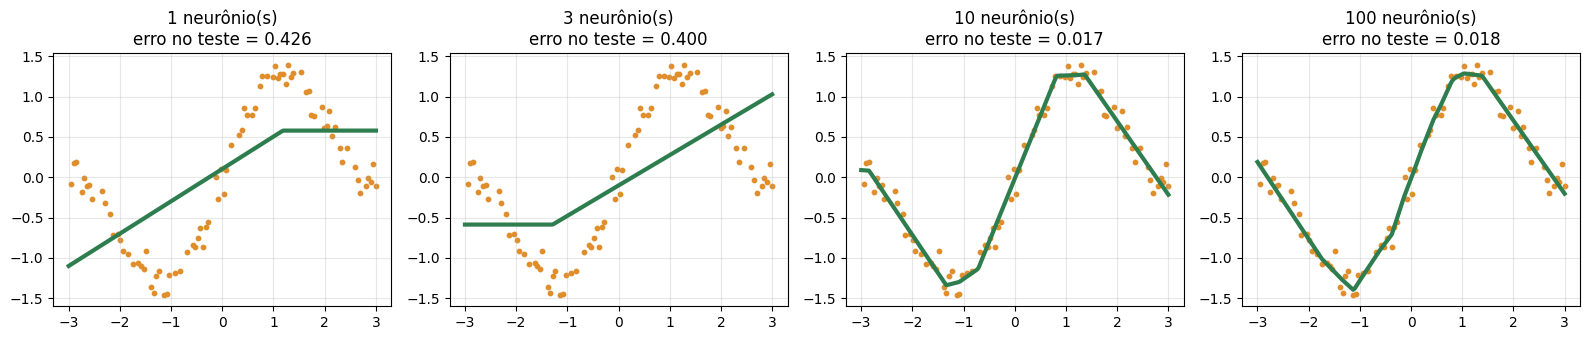

In [ ]:
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.5))

for eixo, n in zip(eixos, [1, 3, 10, 100]):
    torch.manual_seed(42)
    modelo = nn.Sequential(nn.Linear(1, n), nn.ReLU(), nn.Linear(n, 1))
    treinar(modelo, X_treino, Y_treino)

    with torch.no_grad():
        erro_teste = perda_fn(modelo(X_teste), Y_teste).item()
        eixo.plot(x_grade, modelo(x_grade), color=VERDE, linewidth=3)

    eixo.scatter(x_treino, y_treino, color=LARANJA, s=10)
    eixo.set_title(f"{n} neurônio(s)\nerro no teste = {erro_teste:.3f}")
    eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Com **1 ou 3 neurônios**, a rede não acompanha a curva: há poucas "dobras" disponíveis. Com tão poucos neurônios, basta um deles ficar inativo (sempre zerado pela ReLU) para a rede perder a flexibilidade.
- A partir de **10 neurônios**, o ajuste fica bom.
- Ir para **100 neurônios** não melhora o teste: mais parâmetros do que o problema precisa não ajudam.

Escolher o tamanho da rede é uma decisão prática que voltará várias vezes no curso.

---
## 8. Usando o modelo para prever
---

Depois de treinado, o modelo funciona como uma função comum: damos um $x$, ele devolve um $y$.

In [ ]:
novos_x = torch.tensor([[-2.0], [0.0], [1.0], [2.5]])

with torch.no_grad():
    previsoes = rede(novos_x)

for xv, yv in zip(novos_x, previsoes):
    print(f"x = {xv.item():5.1f}  ->  y previsto = {yv.item():6.3f}")

x =  -2.0  ->  y previsto = -0.698
x =   0.0  ->  y previsto = -0.004
x =   1.0  ->  y previsto =  1.289
x =   2.5  ->  y previsto =  0.259


---
## Exercícios
---

**1.** Troque `nn.ReLU()` por `nn.Tanh()` na rede da Seção 4 e treine de novo. A curva ficou diferente? Como?

**2.** Treine a rede com apenas 200 épocas em vez de 2000. O que acontece com o ajuste?

**3.** Crie uma rede com **duas** camadas ocultas de 10 neurônios. Dica: acrescente mais um `nn.Linear(10, 10)` e mais um `nn.ReLU()` no `nn.Sequential`.

**4.** Use a rede treinada para prever $y$ em $x = 10$, um valor bem fora dos dados de treino. O resultado faz sentido?

perda final no treino (Tanh): 0.0135
erro no teste (MSE) - rede ReLU: 0.0165
erro no teste (MSE) - rede Tanh: 0.0132


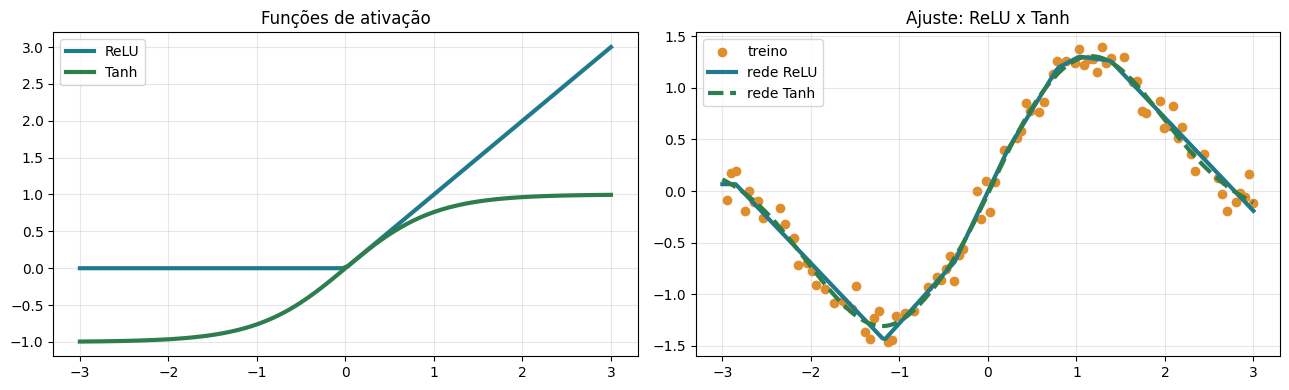

In [ ]:
# ==================================================================================================================
# EXERCÍCIO 1 — Troque nn.ReLU() por nn.Tanh() na rede da Seção 4 e treine de novo. A curva ficou diferente? Como?
# ==================================================================================================================
torch.manual_seed(42)

rede_tanh = nn.Sequential(
    nn.Linear(1, 10),    # camada oculta: 10 neurônios
    nn.Tanh(),           # ativação Tanh no lugar da ReLU
    nn.Linear(10, 1),    # camada de saída
)

hist_tanh = treinar(rede_tanh, X_treino, Y_treino, epocas=2000, lr=0.01)

with torch.no_grad():
    y_tanh = rede_tanh(x_grade)
    erro_tanh = perda_fn(rede_tanh(X_teste), Y_teste).item()

print(f"perda final no treino (Tanh): {hist_tanh[-1]:.4f}")
print(f"erro no teste (MSE) - rede ReLU: {erro_rede:.4f}")
print(f"erro no teste (MSE) - rede Tanh: {erro_tanh:.4f}")

# Comparando as duas funções de ativação
z = torch.linspace(-3, 3, 100)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].plot(z, nn.ReLU()(z), color=AZUL, linewidth=3, label="ReLU")
eixos[0].plot(z, nn.Tanh()(z), color=VERDE, linewidth=3, label="Tanh")
eixos[0].set_title("Funções de ativação"); eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].scatter(x_treino, y_treino, color=LARANJA, label="treino")
eixos[1].plot(x_grade, y_rede, color=AZUL, linewidth=3, label="rede ReLU")
eixos[1].plot(x_grade, y_tanh, color=VERDE, linewidth=3, linestyle="--", label="rede Tanh")
eixos[1].set_title("Ajuste: ReLU x Tanh"); eixos[1].legend(); eixos[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



------------------------------------------------------------
RESPOSTA EXERCÍCIO 01:


Sim, a curva muda de forma, embora as duas sigam bem os dados.
- Com ReLU, a curva é formada por pedaços de reta ("dobras").
  Ela é linear por partes, com cantos nos pontos onde algum neurônio passa de zero para positivo.
- Com Tanh, a curva é suave, sem cantos. A Tanh é uma função em forma de "S" que vai suavemente de -1 a +1, então a soma de várias Tanh produz curvas arredondadas.
- Outra diferença: a Tanh satura (fica perto de -1 ou +1) para entradas grandes. Por isso, longe dos dados, a rede Tanh tende a ficar "achatada" (constante), enquanto a ReLU segue em linha reta.
- Os erros no teste das duas ficam baixos e próximos. Para este problema, as duas ativações funcionam.
------------------------------------------------------------

200 épocas  -> perda treino: 0.0214 | erro teste: 0.0225
2000 épocas -> perda treino: 0.0147 | erro teste: 0.0167


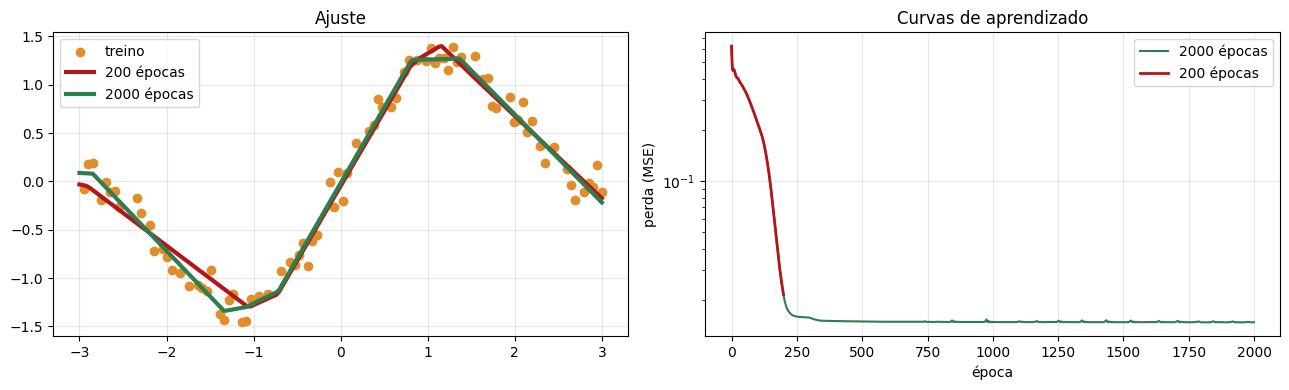

In [ ]:
# ===============================================================================================
# EXERCÍCIO 2 — Treine a rede com apenas 200 épocas em vez de 2000. O que acontece com o ajuste?
# ===============================================================================================
# Usamos a mesma semente para as duas redes começarem com os
# mesmos parâmetros iniciais. Assim, a única diferença é o
# número de épocas.
torch.manual_seed(42)
rede_200 = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
hist_200 = treinar(rede_200, X_treino, Y_treino, epocas=200)

torch.manual_seed(42)
rede_2000 = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
hist_2000 = treinar(rede_2000, X_treino, Y_treino, epocas=2000)

with torch.no_grad():
    y_200  = rede_200(x_grade)
    y_2000 = rede_2000(x_grade)
    erro_200  = perda_fn(rede_200(X_teste),  Y_teste).item()
    erro_2000 = perda_fn(rede_2000(X_teste), Y_teste).item()

print(f"200 épocas  -> perda treino: {hist_200[-1]:.4f} | erro teste: {erro_200:.4f}")
print(f"2000 épocas -> perda treino: {hist_2000[-1]:.4f} | erro teste: {erro_2000:.4f}")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].scatter(x_treino, y_treino, color=LARANJA, label="treino")
eixos[0].plot(x_grade, y_200,  color=VERMELHO, linewidth=3, label="200 épocas")
eixos[0].plot(x_grade, y_2000, color=VERDE,    linewidth=3, label="2000 épocas")
eixos[0].set_title("Ajuste"); eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].plot(hist_2000, color=VERDE, label="2000 épocas")
eixos[1].plot(hist_200,  color=VERMELHO, linewidth=2, label="200 épocas")
eixos[1].set_yscale("log"); eixos[1].set_xlabel("época"); eixos[1].set_ylabel("perda (MSE)")
eixos[1].set_title("Curvas de aprendizado"); eixos[1].legend(); eixos[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



------------------------------------------------------------

RESPOSTA EXERCÍCIO 02:

Com 200 épocas o treinamento é interrompido cedo demais. A perda ainda está caindo, como mostra a curva de aprendizado.
O ajuste fica pior: a curva já tem o formato geral (sobe, desce, sobe), mas não acompanha bem os picos e vales dos dados. Os erros de treino e de teste são maiores que com 2000 épocas.
Isso é um caso de SUBAJUSTE (underfitting). O modelo tem capacidade para aprender a curva, mas não teve passos de otimização suficientes. A curva de aprendizado ajuda a diagnosticar isso: se a perda ainda está caindo quando o treino para, vale treinar por mais épocas.

------------------------------------------------------------

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): ReLU()
  (4): Linear(in_features=10, out_features=1, bias=True)
)
total de parâmetros: 141
perda final no treino (2 camadas): 0.0124
erro no teste (MSE) - 1 camada : 0.0165
erro no teste (MSE) - 2 camadas: 0.0139


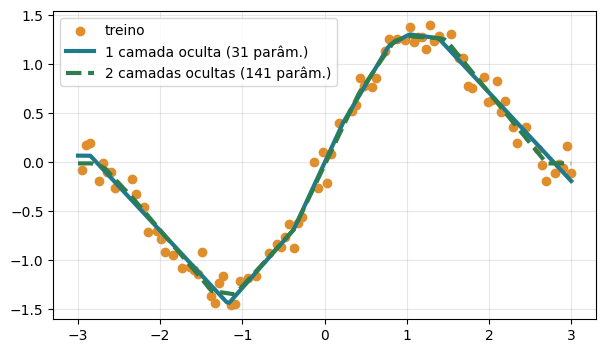

In [ ]:
# ==================================================================================
# EXERCÍCIO 3 — Crie uma rede com duas camadas ocultas de 10 neurônios.
# Dica: acrescente mais um nn.Linear(10, 10) e mais um nn.ReLU() no nn.Sequential.
# ==================================================================================
torch.manual_seed(42)

rede_2camadas = nn.Sequential(
    nn.Linear(1, 10),    # 1ª camada oculta: 10 neurônios
    nn.ReLU(),
    nn.Linear(10, 10),   # 2ª camada oculta: 10 neurônios
    nn.ReLU(),
    nn.Linear(10, 1),    # camada de saída
)
print(rede_2camadas)

# Contando os parâmetros
total = 0
for p in rede_2camadas.parameters():
    total = total + p.numel()
print("total de parâmetros:", total)   # (10+10) + (100+10) + (10+1) = 141

hist_2c = treinar(rede_2camadas, X_treino, Y_treino, epocas=2000)

with torch.no_grad():
    y_2c = rede_2camadas(x_grade)
    erro_2c = perda_fn(rede_2camadas(X_teste), Y_teste).item()

print(f"perda final no treino (2 camadas): {hist_2c[-1]:.4f}")
print(f"erro no teste (MSE) - 1 camada : {erro_rede:.4f}")
print(f"erro no teste (MSE) - 2 camadas: {erro_2c:.4f}")

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_rede, color=AZUL,  linewidth=3, label="1 camada oculta (31 parâm.)")
plt.plot(x_grade, y_2c,   color=VERDE, linewidth=3, linestyle="--", label="2 camadas ocultas (141 parâm.)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()



------------------------------------------------------------

RESPOSTA EXERCÍCIO 03:

A rede com duas camadas ocultas tem 141 parâmetros, contra 31 da rede original:

  1ª camada: 1x10 pesos + 10 vieses   =  20

  2ª camada: 10x10 pesos + 10 vieses  = 110
  
  saída    : 10x1 pesos + 1 viés      =  11

Ela também aprende a curva, e o erro no teste fica parecido com o da rede de uma camada. A segunda camada combina as "dobras" da primeira e gera mais dobras, o que aumenta a flexibilidade.
Para este problema simples (uma curva suave em 1 dimensão), uma camada com 10 neurônios já basta. Por isso, a camada extra não traz ganho expressivo. Redes mais profundas fazem mais diferença em problemas mais complexos.

------------------------------------------------------------

x = 10 -> previsão rede ReLU: -6.501
x = 10 -> previsão rede Tanh: -0.458
x = 10 -> valor real (sem ruído): 3.650


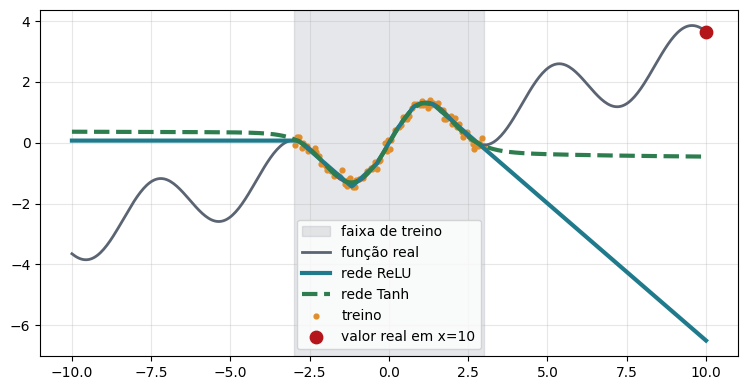

In [ ]:
# ============================================================================================================================
# EXERCÍCIO 4 — Use a rede treinada para prever  y  em  x=10 , um valor bem fora dos dados de treino. O resultado faz sentido?
# ============================================================================================================================
x_novo = torch.tensor([[10.0]])

with torch.no_grad():
    y_prev_relu = rede(x_novo).item()
    y_prev_tanh = rede_tanh(x_novo).item()     # rede do Exercício 1

# Valor "verdadeiro" (sem ruído) da função que gerou os dados
y_real = np.sin(1.5 * 10) + 0.3 * 10

print(f"x = 10 -> previsão rede ReLU: {y_prev_relu:.3f}")
print(f"x = 10 -> previsão rede Tanh: {y_prev_tanh:.3f}")
print(f"x = 10 -> valor real (sem ruído): {y_real:.3f}")

# Visualizando o comportamento da rede fora da faixa [-3, 3]
x_longe = torch.linspace(-10, 10, 400).reshape(-1, 1)
with torch.no_grad():
    y_longe_relu = rede(x_longe)
    y_longe_tanh = rede_tanh(x_longe)
y_longe_real = np.sin(1.5 * x_longe.numpy()) + 0.3 * x_longe.numpy()

plt.figure(figsize=(9, 4.5))
plt.axvspan(-3, 3, color=CINZA, alpha=0.15, label="faixa de treino")
plt.plot(x_longe, y_longe_real, color=CINZA, linewidth=2, label="função real")
plt.plot(x_longe, y_longe_relu, color=AZUL,  linewidth=3, label="rede ReLU")
plt.plot(x_longe, y_longe_tanh, color=VERDE, linewidth=3, linestyle="--", label="rede Tanh")
plt.scatter(x_treino, y_treino, color=LARANJA, s=12, label="treino")
plt.scatter([10], [y_real], color=VERMELHO, s=80, zorder=5, label="valor real em x=10")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


------------------------------------------------------------

RESPOSTA EXERCÍCIO 04:

O resultado não faz sentido. O valor real seria sin(15) + 3 ≈ 3.65, e a previsão da rede fica bem longe disso.

Isso acontece porque a rede só aprendeu o comportamento dos dados no intervalo de treino [-3, 3]. Fora dele, ela não tem nenhuma informação sobre a função:

- A rede ReLU, fora dos dados, continua em LINHA RETA, prolongando o último "pedaço" de reta que aprendeu. Ela não sabe que a curva continua oscilando e subindo.

- A rede Tanh fica praticamente CONSTANTE longe dos dados, porque os neurônios saturam em -1 ou +1.

Lição: redes neurais são boas para INTERPOLAR (prever dentro da faixa dos dados de treino), mas não são confiáveis para EXTRAPOLAR (prever muito fora dela). Antes de usar um modelo, verifique se os novos dados estão na mesma faixa dos dados de
treino.

------------------------------------------------------------